# Testing sensitivity: cases vs wastewater vs both (re-run)

One-at-a-time sensitivity analysis of the testing assumptions in a Covasim outbreak
(10,000 agents, 16 seeded infections, 120 days, 100 random seeds per setting).
For each run, three linear models predict true infections (`burden`): cases only,
wastewater only, and both. The summary is the **median adjusted R²** across runs,
with an **error band** (interquartile range across runs, or a bootstrap 95% CI of the median).

**Run order:** 1 imports and checks, 2 extractor, 3 config, 4 `run_one_config`, 5 small timing test,
6 the `symp_prob` sweep, 7 summary table, 8 the plot, 9 diagnostics (why does "both" change?).
Cells 10 and 11 are optional (the other two sweeps).

**Every run is saved** (one row per simulation) to a CSV after each setting, and a re-run skips settings
already in the CSV, so a crash or a stopped kernel does not lose finished work.

## 1. Imports and checks

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm      # was missing from the original notebook
import covasim as cv

print("Covasim", cv.__version__)

# The wastewater signal needs viral_shedding_hist, which is not in standard Covasim.
# Check that this kernel has it before spending time on the full run.
_t = cv.Sim(pop_size=500, n_days=10, verbose=0)
_t.run()
try:
    _ = _t.results["viral_shedding_hist"]
    print("viral_shedding_hist found")
except KeyError:
    raise RuntimeError("This kernel's Covasim has no 'viral_shedding_hist'. "
                       "Select the kernel/environment with the team's Covasim branch.")

Covasim 3.1.8 (2026-05-29) — © 2020-2026 by IDM
Covasim 3.1.8
viral_shedding_hist found


## 2. Extract burden / cases / wastewater from a finished sim

In [2]:
def extract_wastewater_regression_data(sim) -> pd.DataFrame:
    """
    Daily (burden, cases, wastewater) from a finished Covasim sim.
        burden     -> new_infections   (true, unobserved)
        cases      -> new_diagnoses    (needs a testing intervention, otherwise all zeros)
        wastewater -> viral_shedding_hist summed across agents, per day
    """
    results = sim.results

    burden = np.asarray(results["new_infections"].values, dtype=float)

    if "new_diagnoses" not in results:
        raise KeyError("sim.results has no 'new_diagnoses' - did the sim run?")
    cases = np.asarray(results["new_diagnoses"].values, dtype=float)
    if cases.sum() == 0:
        print("Warning: 'cases' (new_diagnoses) is all zero. Add a testing intervention.")

    viral_shedding_hist = np.asarray(results["viral_shedding_hist"])      # (n_people, n_days)
    wastewater = viral_shedding_hist.sum(axis=0)

    n = len(burden)
    return pd.DataFrame({
        "day": np.arange(n),
        "date": [sim.date(d) for d in range(n)],
        "burden": burden,
        "cases": cases,
        "wastewater": wastewater[:n],
    })

## 3. Config (the settings of the original analysis)

In [18]:
POP_SIZE = 10_000
POP_INFECTED = 16                   # about 0.16% of the population
N_DAYS = 120
N_RUNS = 100                        # random seeds per parameter setting
FIZZLE_THRESHOLD = 0.01 * POP_SIZE  # skip runs where under 1% of the population was ever infected

# Values held fixed while one parameter is swept
BASELINE = dict(symp_prob=0.03, asymp_prob=0.002, test_delay=4)
ISO_FACTOR = dict(h=0.4, s=0.1, w=0.1, c=0.1)       # constant in every simulation

# One-at-a-time sweeps

#SWEEP ONE
SWEEPS0 = {
    "symp_prob":  [0.01, 0.03, 0.10, 0.30],
    "asymp_prob": [0.0, 0.002, 0.01, 0.05],
    "test_delay": [1, 3, 7, 10],
}

SWEEPS = {
    "symp_prob":  [0.01, 0.03, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40],
    "asymp_prob": [0.0, 0.002, 0.01, 0.05],
    "test_delay": [1, 3, 7, 10],
}

OUT_DIR = Path("sensitivity_rerun")
OUT_DIR.mkdir(exist_ok=True)
PER_RUN_CSV = OUT_DIR / "per_run_results.csv"             # one row per simulation (the raw record)
SUMMARY_CSV = OUT_DIR / "sensitivity_summary.csv"        # medians and bands per setting
print("per-run results will be saved to", PER_RUN_CSV.resolve())

per-run results will be saved to /storage/hcraddock/GitHub/covasim4wastewater/modeling/analysis_sandiego_cases_waste_water/sensitivity_rerun/per_run_results.csv


## 4. Run one parameter setting (100 stochastic simulations, three models each)
Returns one row per simulation, so the spread across runs is kept.

In [19]:
def run_one_config(param_name, param_value, n_runs=N_RUNS):
    """Run n_runs stochastic sims at one setting (others at BASELINE), fit the three
    linear models on each, and return one row per simulation."""
    test_kwargs = dict(BASELINE)
    test_kwargs[param_name] = param_value
    testing = cv.test_prob(**test_kwargs)

    base_sim = cv.Sim(
        pop_size=POP_SIZE,
        pop_type="hybrid",
        pop_infected=POP_INFECTED,
        location="zambia",
        n_days=N_DAYS,
        n_imports=0,
        interventions=[testing],
        iso_factor=ISO_FACTOR,
        verbose=0,
    )

    msim = cv.MultiSim(base_sim, n_runs=n_runs)
    msim.run()

    rows = []
    for i, sim in enumerate(msim.sims):
        df = extract_wastewater_regression_data(sim)
        total_inf = df["burden"].sum()
        rec = dict(param=param_name, value=param_value, run=i,
                   total_infections=total_inf,
                   peak_day=int(df["burden"].to_numpy().argmax()),
                   fizzled=bool(total_inf < FIZZLE_THRESHOLD))
        if not rec["fizzled"]:
            m_cases = smf.ols("burden ~ cases", data=df).fit()
            m_wastewater = smf.ols("burden ~ wastewater", data=df).fit()
            m_both = smf.ols("burden ~ cases + wastewater", data=df).fit()
            rec.update(
                adjr2_cases=m_cases.rsquared_adj,
                adjr2_ww=m_wastewater.rsquared_adj,
                adjr2_both=m_both.rsquared_adj,
                p_add_ww=anova_lm(m_cases, m_both)["Pr(>F)"].iloc[1],          # wastewater adds value beyond cases?
                p_add_cases=anova_lm(m_wastewater, m_both)["Pr(>F)"].iloc[1],  # cases add value beyond wastewater?
                total_diagnoses=df["cases"].sum(),
                corr_cases_ww=df["cases"].corr(df["wastewater"]),               # how similar the two predictors are
            )
        rows.append(rec)

    del msim                          # free the memory held by the stored simulations
    return pd.DataFrame(rows)

## 5. Small timing test (5 simulations, not saved)
Run this first so you know how long the full sweep will take.

In [7]:
t0 = time.time()
test_rows = run_one_config("symp_prob", 0.10, n_runs=5)
print(f"5 simulations took {time.time() - t0:.0f} s")
print(test_rows[["run", "fizzled", "total_infections", "adjr2_cases", "adjr2_ww", "adjr2_both"]].round(3))

5 simulations took 3 s
   run  fizzled  total_infections  adjr2_cases  adjr2_ww  adjr2_both
0    0    False            9804.0        0.739     0.801       0.808
1    1    False           10063.0        0.745     0.807       0.821
2    2    False            9626.0        0.725     0.804       0.821
3    3    False            9458.0        0.734     0.807       0.827
4    4    False            9779.0        0.696     0.798       0.854


## 6. The `symp_prob` sweep (4 settings x 100 simulations = 400 simulations)
Every simulation is saved to the per-run CSV after each setting. If the kernel stops, run this cell again and it carries on from the next unfinished setting.

In [ ]:
def run_sweep(param_names):
    per_run = pd.read_csv(PER_RUN_CSV) if PER_RUN_CSV.exists() else pd.DataFrame()
    for p in param_names:
        for v in SWEEPS[p]:
            if len(per_run) and ((per_run["param"] == p) & np.isclose(per_run["value"].astype(float), v)).any():
                print(f"skip {p} = {v} (already in {PER_RUN_CSV.name})")
                continue
            t0 = time.time()
            print(f"Running {p} = {v} ...", flush=True)
            rows = run_one_config(p, v)
            per_run = pd.concat([per_run, rows], ignore_index=True)
            per_run.to_csv(PER_RUN_CSV, index=False)                    # saved after every setting
            ok = rows[~rows["fizzled"]]
            print(f"   done in {time.time() - t0:.0f} s | used {len(ok)} runs, {int(rows['fizzled'].sum())} fizzled | "
                  f"median adj R2: cases {ok['adjr2_cases'].median():.3f}  wastewater {ok['adjr2_ww'].median():.3f}  "
                  f"both {ok['adjr2_both'].median():.3f}", flush=True)
    return per_run

per_run = run_sweep(["symp_prob"])
#per_run2 = run_sweep(["symp_prob"])

skip symp_prob = 0.01 (already in per_run_results.csv)
skip symp_prob = 0.03 (already in per_run_results.csv)
skip symp_prob = 0.1 (already in per_run_results.csv)
skip symp_prob = 0.15 (already in per_run_results.csv)
skip symp_prob = 0.2 (already in per_run_results.csv)
Running symp_prob = 0.25 ...
   done in 14 s | used 100 runs, 0 fizzled | median adj R2: cases 0.783  wastewater 0.809  both 0.811
skip symp_prob = 0.3 (already in per_run_results.csv)
Running symp_prob = 0.35 ...
   done in 17 s | used 100 runs, 0 fizzled | median adj R2: cases 0.812  wastewater 0.812  both 0.816
Running symp_prob = 0.4 ...
   done in 16 s | used 100 runs, 0 fizzled | median adj R2: cases 0.822  wastewater 0.811  both 0.822
skip symp_prob = 0.01 (already in per_run_results.csv)
skip symp_prob = 0.03 (already in per_run_results.csv)
skip symp_prob = 0.1 (already in per_run_results.csv)
skip symp_prob = 0.15 (already in per_run_results.csv)
skip symp_prob = 0.2 (already in per_run_results.csv)
skip sym

## 7. Summary per setting: medians, interquartile range, and a bootstrap 95% CI of the median

In [ ]:
MODELS = {"cases": "adjr2_cases", "wastewater": "adjr2_ww", "both": "adjr2_both"}

def summarise(per_run, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    out = []
    for (p, v), g in per_run.groupby(["param", "value"], sort=False):
        ok = g[~g["fizzled"].astype(bool)]
        row = dict(param=p, value=v, n_used=len(ok), n_fizzled=int(g["fizzled"].astype(bool).sum()))
        for name, col in MODELS.items():
            x = ok[col].dropna().to_numpy()
            if len(x) == 0:
                row.update({f"median_AdjR2_{name}": np.nan, f"q25_{name}": np.nan, f"q75_{name}": np.nan,
                            f"ci_low_{name}": np.nan, f"ci_high_{name}": np.nan})
                continue
            boot = np.median(rng.choice(x, size=(n_boot, len(x)), replace=True), axis=1)
            row[f"median_AdjR2_{name}"] = np.median(x)
            row[f"q25_{name}"], row[f"q75_{name}"] = np.percentile(x, [25, 75])         # spread across runs
            row[f"ci_low_{name}"], row[f"ci_high_{name}"] = np.percentile(boot, [2.5, 97.5])  # uncertainty in the median
        row["pct_ww_helps"] = np.mean(ok["p_add_ww"] < 0.05) * 100 if len(ok) else np.nan
        row["pct_cases_helps"] = np.mean(ok["p_add_cases"] < 0.05) * 100 if len(ok) else np.nan
        row["median_total_infections"] = ok["total_infections"].median()
        row["median_peak_day"] = ok["peak_day"].median()
        row["median_corr_cases_ww"] = ok["corr_cases_ww"].median()
        out.append(row)
    return pd.DataFrame(out)

results = summarise(per_run)
results.to_csv(SUMMARY_CSV, index=False)
results[results["param"] == "symp_prob"].round(3)


,param,value,n_used,n_fizzled,median_AdjR2_cases,q25_cases,q75_cases,ci_low_cases,ci_high_cases,median_AdjR2_wastewater,...,median_AdjR2_both,q25_both,q75_both,ci_low_both,ci_high_both,pct_ww_helps,pct_cases_helps,median_total_infections,median_peak_day,median_corr_cases_ww
0,symp_prob,0.01,100,0,0.579,0.549,0.618,0.565,0.599,0.804,...,0.816,0.808,0.827,0.813,0.819,100.0,74.0,9983.5,51.0,0.907
1,symp_prob,0.03,100,0,0.656,0.636,0.674,0.649,0.666,0.804,...,0.835,0.826,0.847,0.832,0.839,100.0,97.0,9913.5,50.0,0.959
2,symp_prob,0.10,100,0,0.721,0.710,0.735,0.717,0.726,0.807,...,0.834,0.826,0.842,0.831,0.837,100.0,99.0,9691.0,50.0,0.982
3,symp_prob,0.30,100,0,0.798,0.789,0.809,0.795,0.802,0.813,...,0.813,0.805,0.818,0.811,0.815,83.0,8.0,9292.0,52.0,0.990
4,symp_prob,0.15,100,0,0.746,0.734,0.757,0.741,0.750,0.807,...,0.826,0.816,0.836,0.823,0.830,100.0,89.0,9581.5,51.0,0.986
5,symp_prob,0.20,100,0,0.767,0.757,0.778,0.763,0.771,0.809,...,0.817,0.811,0.824,0.815,0.819,100.0,61.0,9472.0,51.0,0.989


In [12]:
results

,param,value,n_used,n_fizzled,median_AdjR2_cases,q25_cases,q75_cases,ci_low_cases,ci_high_cases,median_AdjR2_wastewater,...,median_AdjR2_both,q25_both,q75_both,ci_low_both,ci_high_both,pct_ww_helps,pct_cases_helps,median_total_infections,median_peak_day,median_corr_cases_ww
0,symp_prob,0.01,100,0,0.579026,0.549226,0.617933,0.564780,0.598613,0.804014,...,0.815790,0.807929,0.827321,0.812728,0.819491,100.0,74.0,9983.5,51.0,0.906520
1,symp_prob,0.03,100,0,0.655716,0.635553,0.673570,0.649175,0.665916,0.803973,...,0.834933,0.825558,0.847328,0.831715,0.838504,100.0,97.0,9913.5,50.0,0.959027
2,symp_prob,0.10,100,0,0.721210,0.710107,0.734693,0.717061,0.725580,0.807434,...,0.834315,0.826342,0.842374,0.831340,0.836664,100.0,99.0,9691.0,50.0,0.982038
3,symp_prob,0.30,100,0,0.797936,0.789200,0.808626,0.794512,0.801652,0.812892,...,0.812807,0.804788,0.817843,0.810517,0.815448,83.0,8.0,9292.0,52.0,0.990401


## 8. The plot
Cases black, wastewater cornflowerblue, both dashed dark blue; top and right axis lines removed; x axis starts at 0.
`BAND = "iqr"` shades the middle 50% of runs (run-to-run spread). `BAND = "ci"` shades a bootstrap 95% CI of the median (how well the median itself is pinned down).

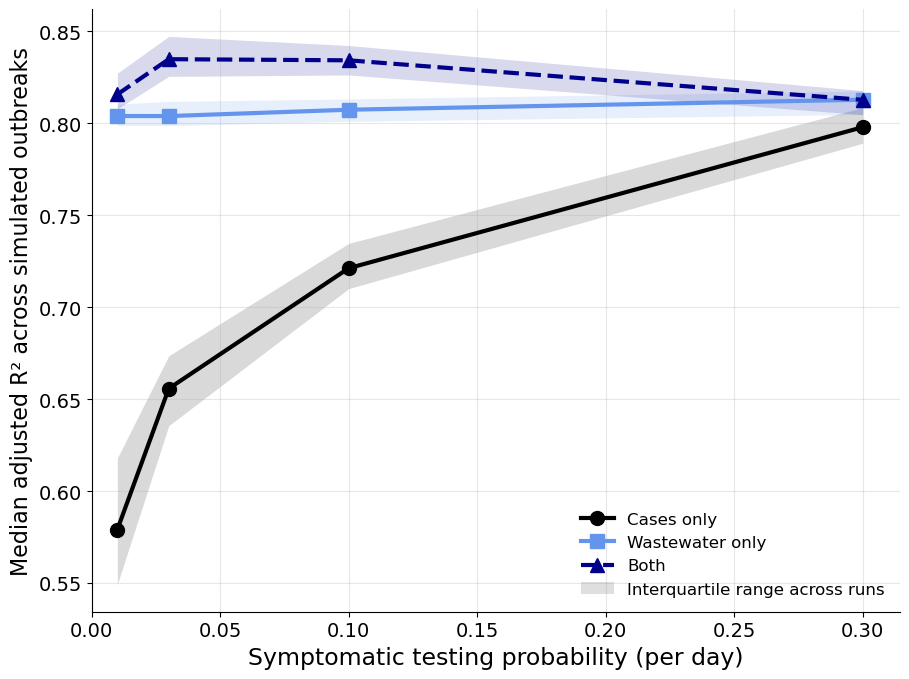

Saved sensitivity_rerun/sensitivity_symp_prob_adjR2.png


In [10]:
from matplotlib.patches import Patch

BAND = "iqr"        # "iqr" or "ci"

STYLES = [   # model, legend label, colour, line style, marker
    ("cases",      "Cases only",      "black",          "-",  "o"),
    ("wastewater", "Wastewater only", "cornflowerblue", "-",  "s"),
    ("both",       "Both",            "darkblue",       "--", "^"),
]
BAND_LABEL = {"iqr": "Interquartile range across runs", "ci": "95% CI of the median (bootstrap)"}

def draw_adjr2(ax, results, param, band=BAND, fs=14):
    sub = results[results["param"] == param].sort_values("value")
    x = sub["value"].astype(float)
    lo, hi = ("q25", "q75") if band == "iqr" else ("ci_low", "ci_high")
    for name, label, color, ls, mk in STYLES:
        ax.fill_between(x, sub[f"{lo}_{name}"], sub[f"{hi}_{name}"], color=color, alpha=0.15, linewidth=0)
        ax.plot(x, sub[f"median_AdjR2_{name}"], ls=ls, marker=mk, color=color, lw=3, ms=10, label=label, clip_on=False)
    ax.set_xlim(left=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(alpha=0.3)
    handles, labels = ax.get_legend_handles_labels()
    handles.append(Patch(facecolor="gray", alpha=0.25, label=BAND_LABEL[band]))
    ax.legend(handles=handles, fontsize=fs - 2, loc="lower right", frameon=False)

def plot_symp_prob(results, band=BAND, save_to=None):
    fig, ax = plt.subplots(figsize=(9.2, 6.9))
    draw_adjr2(ax, results, "symp_prob", band)
    ax.set_xlabel("Symptomatic testing probability (per day)", fontsize=17)
    ax.set_ylabel("Median adjusted R\u00b2 across simulated outbreaks", fontsize=16)
    ax.tick_params(labelsize=14)
    fig.tight_layout()
    if save_to:
        fig.savefig(save_to, dpi=200)
    plt.show()

plot_symp_prob(results, save_to=OUT_DIR / "sensitivity_symp_prob_adjR2.png")
print("Saved", OUT_DIR / "sensitivity_symp_prob_adjR2.png")

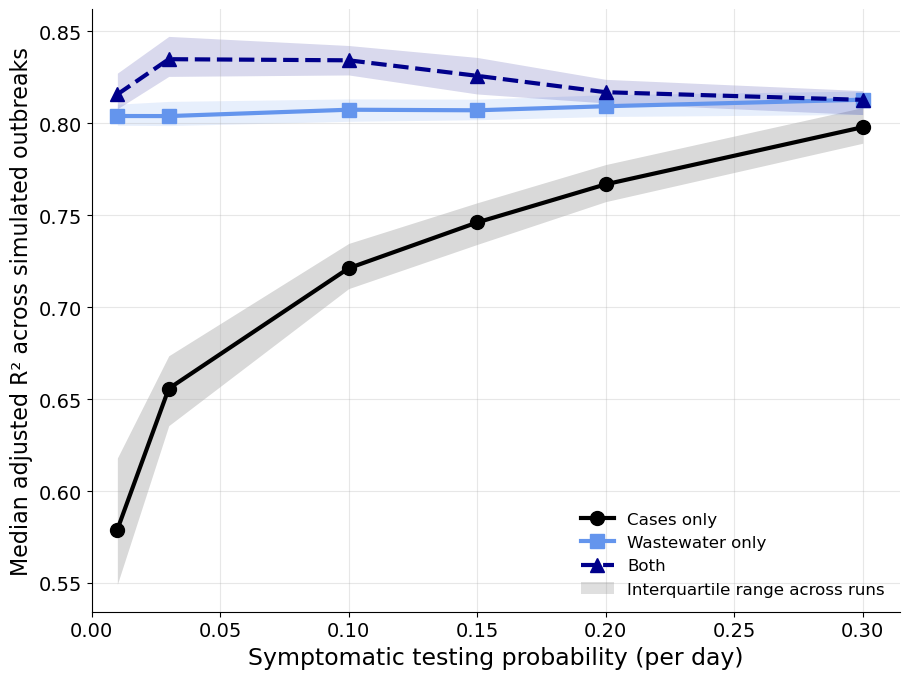

Saved sensitivity_rerun/sensitivity_symp_prob_adjR2.png


In [16]:
from matplotlib.patches import Patch

BAND = "iqr"        # "iqr" or "ci"

STYLES = [   # model, legend label, colour, line style, marker
    ("cases",      "Cases only",      "black",          "-",  "o"),
    ("wastewater", "Wastewater only", "cornflowerblue", "-",  "s"),
    ("both",       "Both",            "darkblue",       "--", "^"),
]
BAND_LABEL = {"iqr": "Interquartile range across runs", "ci": "95% CI of the median (bootstrap)"}

def draw_adjr2(ax, results, param, band=BAND, fs=14):
    sub = results[results["param"] == param].sort_values("value")
    x = sub["value"].astype(float)
    lo, hi = ("q25", "q75") if band == "iqr" else ("ci_low", "ci_high")
    for name, label, color, ls, mk in STYLES:
        ax.fill_between(x, sub[f"{lo}_{name}"], sub[f"{hi}_{name}"], color=color, alpha=0.15, linewidth=0)
        ax.plot(x, sub[f"median_AdjR2_{name}"], ls=ls, marker=mk, color=color, lw=3, ms=10, label=label, clip_on=False)
    ax.set_xlim(left=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(alpha=0.3)
    handles, labels = ax.get_legend_handles_labels()
    handles.append(Patch(facecolor="gray", alpha=0.25, label=BAND_LABEL[band]))
    ax.legend(handles=handles, fontsize=fs - 2, loc="lower right", frameon=False)

def plot_symp_prob(results, band=BAND, save_to=None):
    fig, ax = plt.subplots(figsize=(9.2, 6.9))
    draw_adjr2(ax, results, "symp_prob", band)
    ax.set_xlabel("Symptomatic testing probability (per day)", fontsize=17)
    ax.set_ylabel("Median adjusted R\u00b2 across simulated outbreaks", fontsize=16)
    ax.tick_params(labelsize=14)
    fig.tight_layout()
    if save_to:
        fig.savefig(save_to, dpi=200)
    plt.show()

plot_symp_prob(results, save_to=OUT_DIR / "sensitivity_symp_prob_adjR2.png")
print("Saved", OUT_DIR / "sensitivity_symp_prob_adjR2.png")

## 9. Diagnostics: why does "both" change with the testing probability?
Two things can be checked directly from the saved runs.
**(a)** Does testing change the epidemic itself? In Covasim, diagnosed people isolate, so a higher testing probability can change the outbreak's size and timing, not just what is observed.
**(b)** Does adding cases still help once wastewater is in the model? The paired difference (both minus wastewater-only, run by run) says how much cases add, and the correlation says how similar the two predictors are.

In [11]:
ok = per_run[~per_run["fizzled"].astype(bool)].copy()
ok["both_minus_ww"] = ok["adjr2_both"] - ok["adjr2_ww"]
ok["both_minus_cases"] = ok["adjr2_both"] - ok["adjr2_cases"]

diag = (ok[ok["param"] == "symp_prob"]
        .groupby("value")
        .agg(runs_used=("run", "size"),
             median_total_infections=("total_infections", "median"),
             median_peak_day=("peak_day", "median"),
             median_corr_cases_wastewater=("corr_cases_ww", "median"),
             median_both_minus_ww=("both_minus_ww", "median"),
             q25_both_minus_ww=("both_minus_ww", lambda x: x.quantile(0.25)),
             q75_both_minus_ww=("both_minus_ww", lambda x: x.quantile(0.75)),
             share_runs_both_below_ww=("both_minus_ww", lambda x: (x < 0).mean())))
diag.round(3)

,runs_used,median_total_infections,median_peak_day,median_corr_cases_wastewater,median_both_minus_ww,q25_both_minus_ww,q75_both_minus_ww,share_runs_both_below_ww
value,,,,,,,,
0.01,100,9983.5,51.0,0.907,0.013,0.004,0.024,0.12
0.03,100,9913.5,50.0,0.959,0.030,0.020,0.039,0.00
0.10,100,9691.0,50.0,0.982,0.028,0.020,0.034,0.00
0.30,100,9292.0,52.0,0.990,-0.001,-0.001,0.001,0.64


## 10. Optional: the other two sweeps (asymp_prob and test_delay, 800 more simulations)
Only needed for the full 1,200-simulation analysis. Same save-and-resume behaviour as above.

In [ ]:
per_run = run_sweep(["asymp_prob", "test_delay"])
results = summarise(per_run)
results.to_csv(SUMMARY_CSV, index=False)
results.round(3)

## 11. Optional: panels for all three swept parameters

In [ ]:
fig, axes = plt.subplots(1, len(SWEEPS), figsize=(6.5 * len(SWEEPS), 5.5), sharey=True)
for ax, param_name in zip(axes, SWEEPS):
    draw_adjr2(ax, results, param_name, fs=12)
    ax.set_xlabel(param_name, fontsize=13)
axes[0].set_ylabel("Median adjusted R\u00b2 across runs", fontsize=13)
fig.tight_layout()
fig.savefig(OUT_DIR / "sensitivity_analysis_adjR2.png", dpi=150)
plt.show()

fig2, axes2 = plt.subplots(1, len(SWEEPS), figsize=(6.5 * len(SWEEPS), 5.5), sharey=True)
for ax, param_name in zip(axes2, SWEEPS):
    sub = results[results["param"] == param_name].sort_values("value")
    ax.plot(sub["value"], sub["pct_ww_helps"], "s-", color="cornflowerblue", lw=3, ms=9, label="Wastewater adds value beyond cases")
    ax.plot(sub["value"], sub["pct_cases_helps"], "o-", color="black", lw=3, ms=9, label="Cases add value beyond wastewater")
    ax.set_xlabel(param_name, fontsize=13)
    ax.set_xlim(left=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(alpha=0.3)
axes2[0].set_ylabel("% of runs where predictor significantly helps (p<0.05)", fontsize=12)
axes2[0].legend(frameon=False)
fig2.tight_layout()
fig2.savefig(OUT_DIR / "sensitivity_analysis_winrate.png", dpi=150)
plt.show()